# Grid search backtest

Tries every combination in each model's grid: naive, gradient boosting, Greykite, and Chronos-2. Every config is backtested on the same rolling as-of dates and scored on MAE, RMSE, MAPE, WAPE, and bias.

## Setup

All imports live here. The notebook moves to the repo root so it uses the same config and MLflow store as `natgas tune`.

In [1]:
import logging
import os
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
os.environ["HF_HUB_DISABLE_EXPERIMENTAL_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

from natgas.config import load_settings
from natgas.forecasting.backtesting import Backtester
from natgas.forecasting.data import ForecastDataProvider
from natgas.forecasting.models.chronos.ChronosModel import ChronosModel
from natgas.forecasting.models.chronos.ChronosModelConfig import ChronosModelConfig
from natgas.forecasting.optimization import GridSearchOptimizer
from natgas.forecasting.tuning import ModelPublisher, TuningConfig

# Run from the repo root so config files, mlflow.db, and mlruns/ line up
if Path.cwd().name == "experiments":
    os.chdir(Path.cwd().parent)

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
for name in ["natgas", "mlflow", "greykite", "optuna", "huggingface_hub", "transformers", "torch"]:
    logging.getLogger(name).setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Download Chronos-2 once, then stay offline so worker processes do not
# retry Hugging Face and print timeout warnings.
ChronosModel.pipeline_for(ChronosModelConfig().model_id, "cpu")
os.environ["HF_HUB_OFFLINE"] = "1"

# Greykite switches matplotlib to a file backend, so turn inline charts back on
%matplotlib inline

## Data

`ForecastDataProvider` is the only way models get data. Every as-of date gets training data up to that date and the next 30 trading days to score against. The dates are the same in both notebooks, so the results are comparable.

In [2]:
tuning = TuningConfig.from_yaml("config/tuning.yaml")
settings = load_settings()
provider = ForecastDataProvider.from_settings(settings, tuning.horizon_days, tuning.target_column)
as_of_dates = provider.backtest_dates(tuning.backtest_start, tuning.backtest_end, tuning.step_days)

first, last = provider.first_date.date(), provider.last_date.date()
print(f"prices: {first} to {last}, {len(provider.target)} trading days")
print(f"features: {provider.feature_columns}")
print(
    f"{len(as_of_dates)} as-of dates from {as_of_dates[0].date()} to {as_of_dates[-1].date()}, "
    f"{tuning.horizon_days} trading days ahead each"
)

prices: 2015-01-02 to 2026-11-18, 2989 trading days
features: ['hdd', 'cdd', 'christmas_day', 'christmas_day_pre_1', 'christmas_day_pre_2', 'christmas_day_pre_3', 'christmas_day_pre_4', 'christmas_day_post_1', 'christmas_day_post_2', 'christmas_day_post_3', 'christmas_day_post_4', 'columbus_day', 'columbus_day_pre_1', 'columbus_day_pre_2', 'columbus_day_pre_3', 'columbus_day_pre_4', 'columbus_day_post_1', 'columbus_day_post_2', 'columbus_day_post_3', 'columbus_day_post_4', 'independence_day', 'independence_day_pre_1', 'independence_day_pre_2', 'independence_day_pre_3', 'independence_day_pre_4', 'independence_day_post_1', 'independence_day_post_2', 'independence_day_post_3', 'independence_day_post_4', 'juneteenth_national_independence_day', 'juneteenth_national_independence_day_pre_1', 'juneteenth_national_independence_day_pre_2', 'juneteenth_national_independence_day_pre_3', 'juneteenth_national_independence_day_pre_4', 'juneteenth_national_independence_day_post_1', 'juneteenth_nationa

## Search space

Each model's options come from `config/tuning.yaml` (the `grid` key) and map into that model's config class.

In [3]:
spaces = {name: settings.get("grid") for name, settings in tuning.model_settings.items()}
pd.Series(spaces, name="grid").to_frame()

,grid
naive,None
gradient_boosting,"[{'n_lags': [5, 10], 'learning_rate': [0.03, 0.1], 'max_depth': [2, 4], 'use_weather': [True, False]}, {'n_lags': [5..."
greykite,"{'history_years': [2.0, 4.0], 'autoregression_lags': [0, 3], 'use_holidays': [True, False], 'holiday_window': [2, 4]}"
chronos,"[{'context_length': [128, 512, 2048], 'use_weather': [True, False]}, {'context_length': [128, 512, 2048], 'use_weath..."


## Run the backtests

Each config is backtested on every as-of date and logged as a nested MLflow run.

In [4]:
backtester = Backtester(provider, as_of_dates, n_jobs=tuning.n_jobs)
optimizer = GridSearchOptimizer(backtester, tuning.selection_metric)

mlflow.set_tracking_uri(tuning.tracking_uri)
mlflow.set_experiment("natgas-grid-search")
with mlflow.start_run(run_name="grid-search-notebook") as search_run:
    mlflow.set_tag("method", "grid")
    mlflow.log_params({"backtest_count": len(as_of_dates), "horizon_days": tuning.horizon_days})
    summary = optimizer.run(tuning.model_settings)

print(f"{len(summary)} configs backtested, {len(optimizer.failed)} failed")

83 configs backtested, 0 failed


## Results

Lower is better. `skill_vs_naive` above zero means the config beats repeating the last price.

In [5]:
scores = ["mae", "rmse", "mape", "wape", "bias", "skill_vs_naive"]
columns = ["model_name", "config", *scores, "seconds"]
summary[columns].round(4)

,model_name,config,mae,rmse,mape,wape,bias,skill_vs_naive,seconds
0,chronos,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false, ...",5.192000e-01,7.975000e-01,1.311520e+01,1.364740e+01,-4.200000e-02,1.280000e-02,6.0
1,chronos,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": true, ""...",5.200000e-01,8.055000e-01,1.316040e+01,1.366920e+01,-1.770000e-02,1.130000e-02,18.0
2,chronos,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": false, ""use_weekend"": false,...",5.204000e-01,7.774000e-01,1.319230e+01,1.367910e+01,-3.090000e-02,1.060000e-02,3.6
3,chronos,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": true, ""...",5.214000e-01,8.063000e-01,1.320020e+01,1.370560e+01,-1.280000e-02,8.600000e-03,15.5
4,chronos,"{""context_length"": 2048, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false,...",5.225000e-01,8.013000e-01,1.312870e+01,1.373350e+01,-8.120000e-02,6.600000e-03,16.3
...,...,...,...,...,...,...,...,...,...
78,greykite,"{""auto_changepoints"": false, ""autoregression_lags"": 0, ""fit_algorithm"": ""linear"", ""history_years"": 2.0, ""holiday_win...",1.175500e+00,1.638400e+00,3.368870e+01,3.089870e+01,-6.200000e-02,-1.235000e+00,17.9
79,greykite,"{""auto_changepoints"": false, ""autoregression_lags"": 3, ""fit_algorithm"": ""linear"", ""history_years"": 2.0, ""holiday_win...",3.511342e+06,4.403245e+07,1.023401e+08,9.229819e+07,3.511341e+06,-6.676211e+06,75.9
80,greykite,"{""auto_changepoints"": false, ""autoregression_lags"": 3, ""fit_algorithm"": ""linear"", ""history_years"": 2.0, ""holiday_win...",3.511342e+06,4.403245e+07,1.023401e+08,9.229819e+07,3.511341e+06,-6.676211e+06,75.2
81,greykite,"{""auto_changepoints"": false, ""autoregression_lags"": 0, ""fit_algorithm"": ""linear"", ""history_years"": 2.0, ""holiday_win...",7.164851e+06,3.115670e+08,1.838467e+08,1.883333e+08,-1.817843e+06,-1.362273e+07,33.2


## Best config per model

In [6]:
best = optimizer.best_by_model()
best_table = pd.DataFrame(
    {name: {**report.metrics(), "config": report.config.to_json()} for name, report in best.items()}
).T.sort_values("mae")
best_table

,mae,rmse,mape,wape,bias,config
chronos,0.519195,0.797467,13.11523,13.647409,-0.041969,"{""context_length"": 512, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false, ..."
gradient_boosting,0.523613,0.802446,13.554453,13.763543,0.013151,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf"": 20, ""n_lags"":..."
naive,0.525948,0.810657,13.495778,13.824934,0.003694,{}
greykite,0.736198,1.074146,19.356742,19.351493,0.003033,"{""auto_changepoints"": false, ""autoregression_lags"": 3, ""fit_algorithm"": ""linear"", ""history_years"": 4.0, ""holiday_win..."


## Error by model and by days ahead

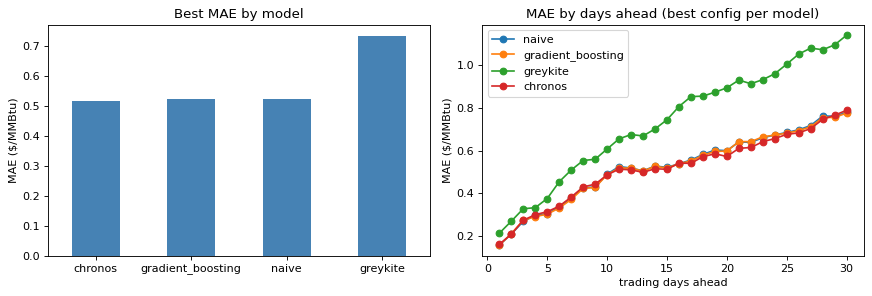

In [7]:
by_step = pd.DataFrame({name: report.metrics_by_step()["mae"] for name, report in best.items()})

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), dpi=80)
best_table["mae"].astype(float).plot.bar(ax=left, color="steelblue")
left.set_title("Best MAE by model")
left.set_ylabel("MAE ($/MMBtu)")
left.tick_params(axis="x", rotation=0)
by_step.plot(ax=right, marker="o")
right.set_title("MAE by days ahead (best config per model)")
right.set_xlabel("trading days ahead")
right.set_ylabel("MAE ($/MMBtu)")
figure.tight_layout()
plt.show()

## Error by horizon bucket

Best config per model, scored on days 1 to 5, 6 to 15, and 16 to 30 ahead.

In [8]:
buckets = pd.concat({name: report.metrics_by_bucket() for name, report in best.items()})
buckets.round(4)

mae    rmse     mape     wape    bias
                  days_ahead                                             
naive             days 1 to 5    0.2476  0.3849   6.1753   6.5001 -0.0015
                  days 6 to 15   0.4656  0.6852  11.9472  12.2125 -0.0047
                  days 16 to 30  0.6589  0.9757  16.9683  17.3540  0.0110
gradient_boosting days 1 to 5    0.2475  0.3906   6.1987   6.4958 -0.0025
                  days 6 to 15   0.4624  0.6760  11.9576  12.1266  0.0081
                  days 16 to 30  0.6565  0.9656  17.0709  17.2900  0.0218
greykite          days 1 to 5    0.3039  0.4521   7.8635   7.9778  0.0105
                  days 6 to 15   0.6123  0.8627  16.1114  16.0604 -0.0075
                  days 16 to 30  0.9629  1.3203  25.3514  25.3584  0.0075
chronos           days 1 to 5    0.2518  0.4016   6.2156   6.6106 -0.0225
                  days 6 to 15   0.4628  0.6787  11.7580  12.1382 -0.0402
                  days 16 to 30  0.6459  0.9545  16.3199  17.0111 -0.0496

## Best config

The publishing rule only picks a model over naive when it lowers error by at least the margin in `tuning.yaml`.

In [9]:
publisher = ModelPublisher(
    provider,
    tuning.registered_model_name,
    tuning.model_alias,
    tuning.selection_metric,
    tuning.min_improvement,
)
decision = publisher.choose(optimizer.reports)
print(decision.reason)
print("model to publish:", decision.report.model_name, decision.report.config.to_json())

chronos beat naive by 1.28%
model to publish: chronos {"context_length": 512, "device": "cpu", "model_id": "amazon/chronos-2", "use_weather": true, "use_weekend": false, "use_yearly": false, "weather_columns": ["hdd", "cdd"], "weekly_harmonics": 0}


## Publish

Retrain the chosen config on all data and register it in the MLflow model registry.

In [10]:
with mlflow.start_run(run_name=f"publish-{decision.report.model_name}"):
    mlflow.set_tags({"search_run_id": search_run.info.run_id, "method": "grid"})
    version = publisher.publish(decision)
print(f"registered {tuning.registered_model_name} version {version} as @{tuning.model_alias}")

Registered model 'natgas-price-forecaster' already exists. Creating a new version of this model...
Created version '7' of model 'natgas-price-forecaster'.


registered natgas-price-forecaster version 7 as @champion
